In [1]:
import os
import cupy as cp
import numpy as np
import matplotlib.pyplot as plt

from airy_pipeline.methods.utilities import write_tiff
from airy_pipeline.methods.utilities import write_h5, read_h5
from aicspylibczi import CziFile
from PIL import Image, ImageDraw, ImageFont
from airy_pipeline.methods import to_directory, read_czi, to_isotropic, read_yaml, read_beads, read_h5, \
     read_shape, read_kernel, to_mip, to_shift, configure_plots, to_shifted, to_ellipsoid, \
     make_color, to_fmt, segmentation, detection, finding, deskewing, deconvolution

In [2]:
# inputs

folder_path = "/mnt/marieshares/Miles/20260529_PcG_bodies/PCGF24/UNT/"
base_path = "/mnt/marieshares/Miles/20260529_PcG_bodies/"
out_path = "/mnt/md1/sumin/PolycombBodies/"
out_sub_path = os.path.join(out_path, folder_path[len(base_path):]) 

os.makedirs(out_sub_path, exist_ok=True) #create the subfolders if they don't exist

# Obtain processed airyscan czi files from folder with "SR2Y" in the name:
files_to_process = [
    f for f in os.listdir(folder_path) 
    if "SR2Y" in f and f.endswith("-processed.czi") and os.path.isfile(os.path.join(folder_path, f))
]

### SPECIFY FILE HERE:
filename = files_to_process[2] ### change index to process different files #2 good
print(filename)
file = os.path.join(folder_path, filename) #change index to process different files

beads = "airy_beads_SR2Y.txt"
psf = "AiryPSF_MKH_SR2Y.h5"
directory = to_directory(file)
config = "airy_config.yaml"

# read CZI and config
czi = CziFile(file)
print(czi.size)
c = read_yaml(config)

# path to steps/nuclei
frames_path = os.path.join(directory, "frames")
nuclei_path = os.path.join(directory, "nuclei")

# get PSF parameters
lasers = c["general"]["lasers"]
kernel = read_kernel(psf, lasers)
shape = read_shape(psf, lasers)

# set GPU and plot formatting
device = 0
configure_plots()

20260529_PCGF24_UNT_RING1B_HT_JFX650_SR2Y-03-processed.czi
(1, 1, 104, 1384, 1384)


In [3]:
# read a frame
print(f"reading and deconvolving {filename}")

signal = read_czi(file, 0) #there is only one frame so index = 0
resampled = to_isotropic(signal, **c["isotropic"])[:,:-5]
#signal = signal[np.newaxis, ...] #need to add another dimension t

# deconvolve all channels
device = 0
with cp.cuda.Device(device):
   deconvolve = deconvolution(resampled, kernel, **c["deconvolution"])

# Deconvolution for one frame takes over 2 minutes. We will save the deconvolved but not use it for segmentation.

reading and deconvolving 20260529_PCGF24_UNT_RING1B_HT_JFX650_SR2Y-03-processed.czi


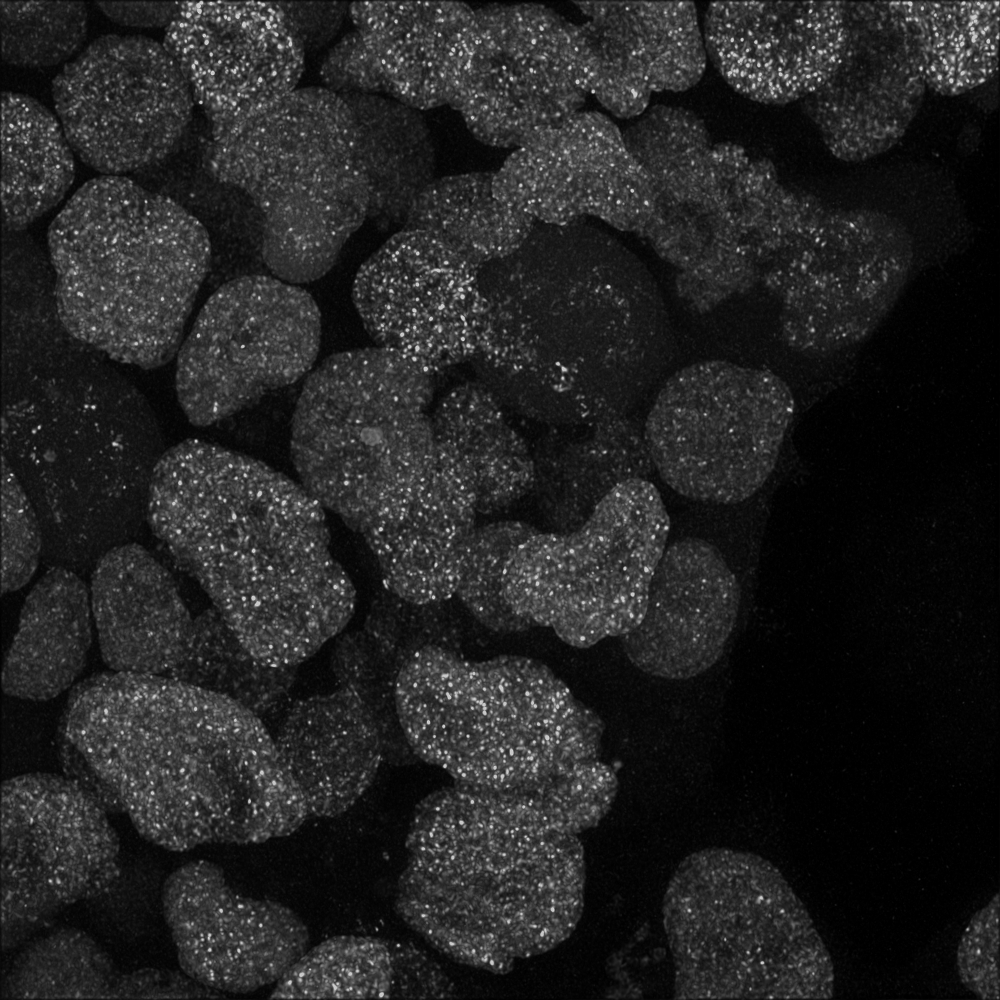

In [7]:
# make MIP
c = read_yaml(config)
chnl = c["segmentation"]["channel"]
mip = to_mip(deconvolve[chnl], **c["movies"]["channels"][chnl], gray=True, axis=0)
mip = np.clip(mip, 0, 200)  # clip for adding labels
display(Image.fromarray(np.transpose(mip, axes=(1,0,2))))

In [8]:
# Nuclear segmentation:

config = "airy_config.yaml"
c = read_yaml(config)

# segment nuclei
with cp.cuda.Device(device):
    labels, info = segmentation(deconvolve, **c["segmentation"])

print(len(info), "nuclei detected" )

18 nuclei detected


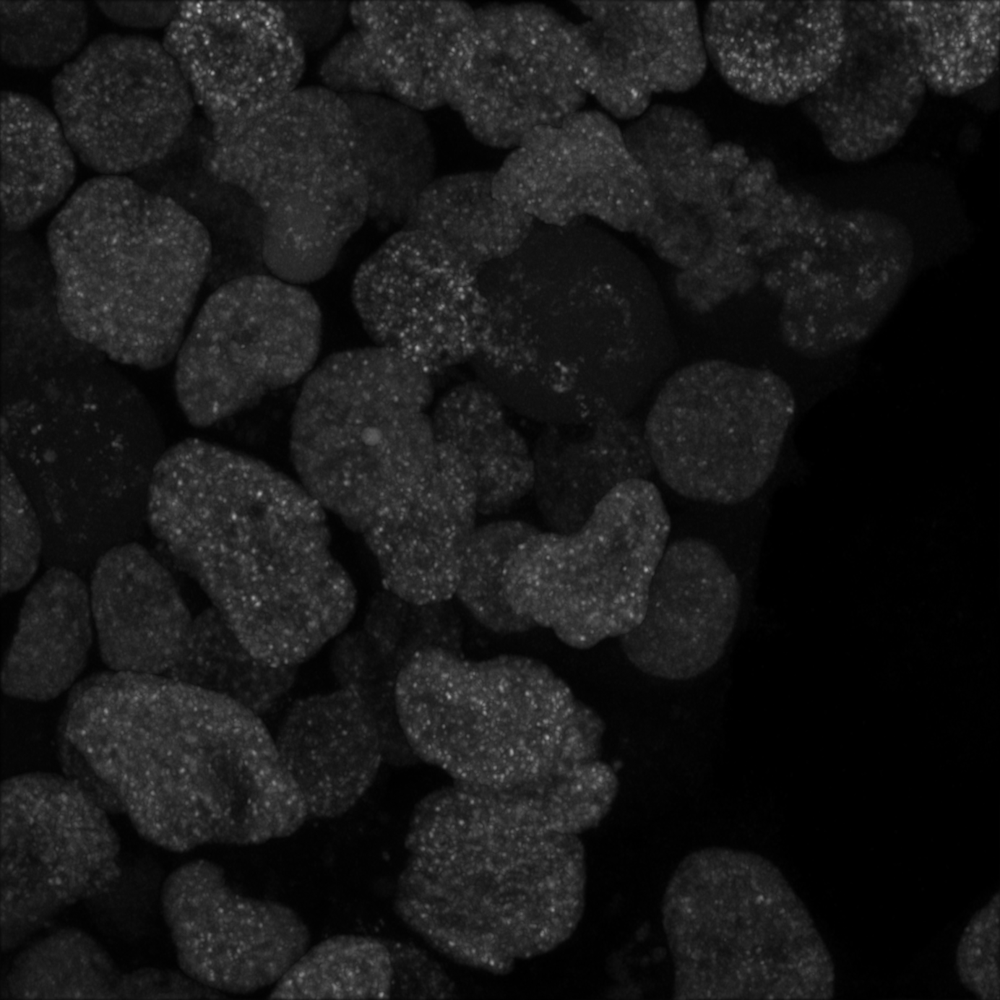

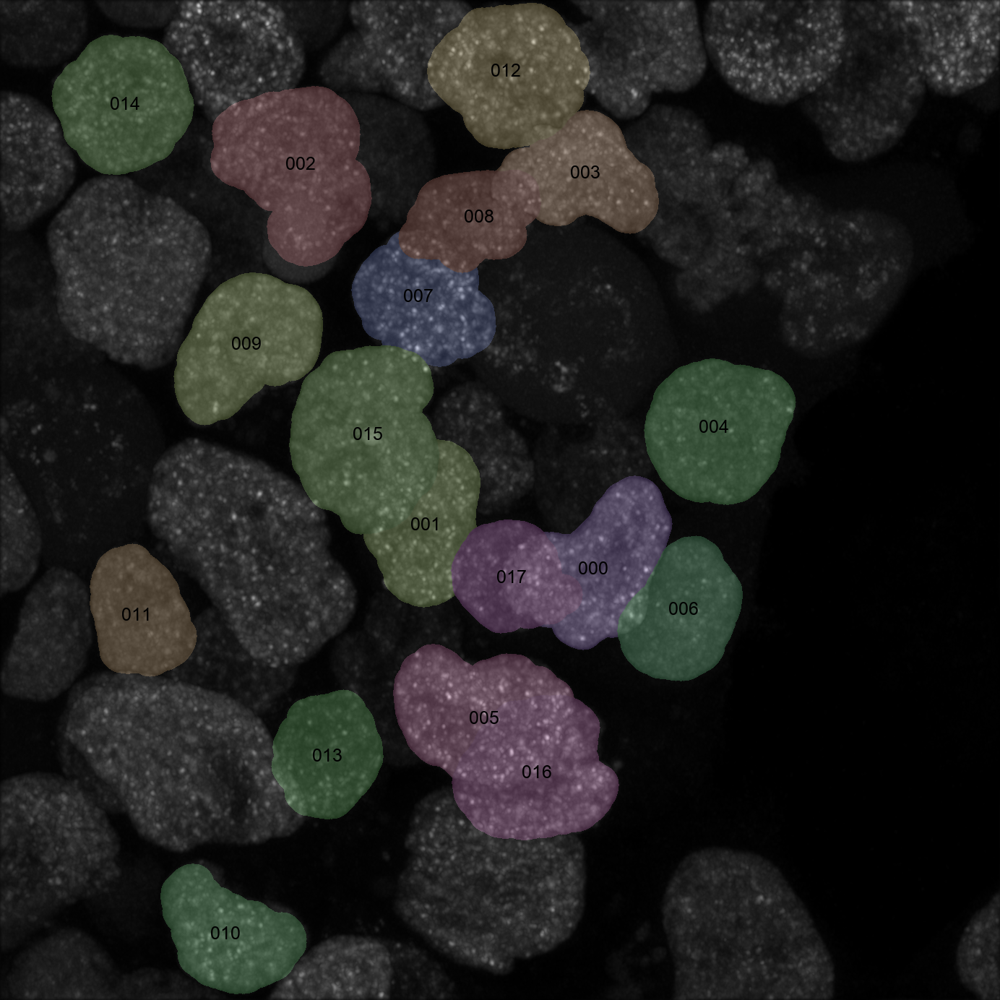

(368, 1384, 1384)


In [9]:
# make MIP
c = read_yaml(config)
chnl = c["segmentation"]["channel"]
mip = to_mip(resampled[chnl], **c["movies"]["channels"][chnl], gray=True, axis=0)
mip = np.clip(mip, 0, 200)  # clip for adding labels
display(Image.fromarray(np.transpose(mip, axes=(1,0,2))))
# add color to MIP
mip_labels = np.max(labels, axis=0)
for i in range(len(info)):
    mip[mip_labels == i] += (55*make_color()).astype(np.uint8)
mip = Image.fromarray(np.transpose(mip, axes=(1,0,2)))

# write labels
draw = ImageDraw.Draw(mip)
for i in range(len(info)):
    x, y, label = info[i,2], info[i,3], i
    draw.text(xy=(x-20,y-15),text=to_fmt(label),
              font=ImageFont.truetype(font="Arial", size=25), fill=(0,0,0))
display(mip)

labels_dims = labels.shape
print(labels_dims)

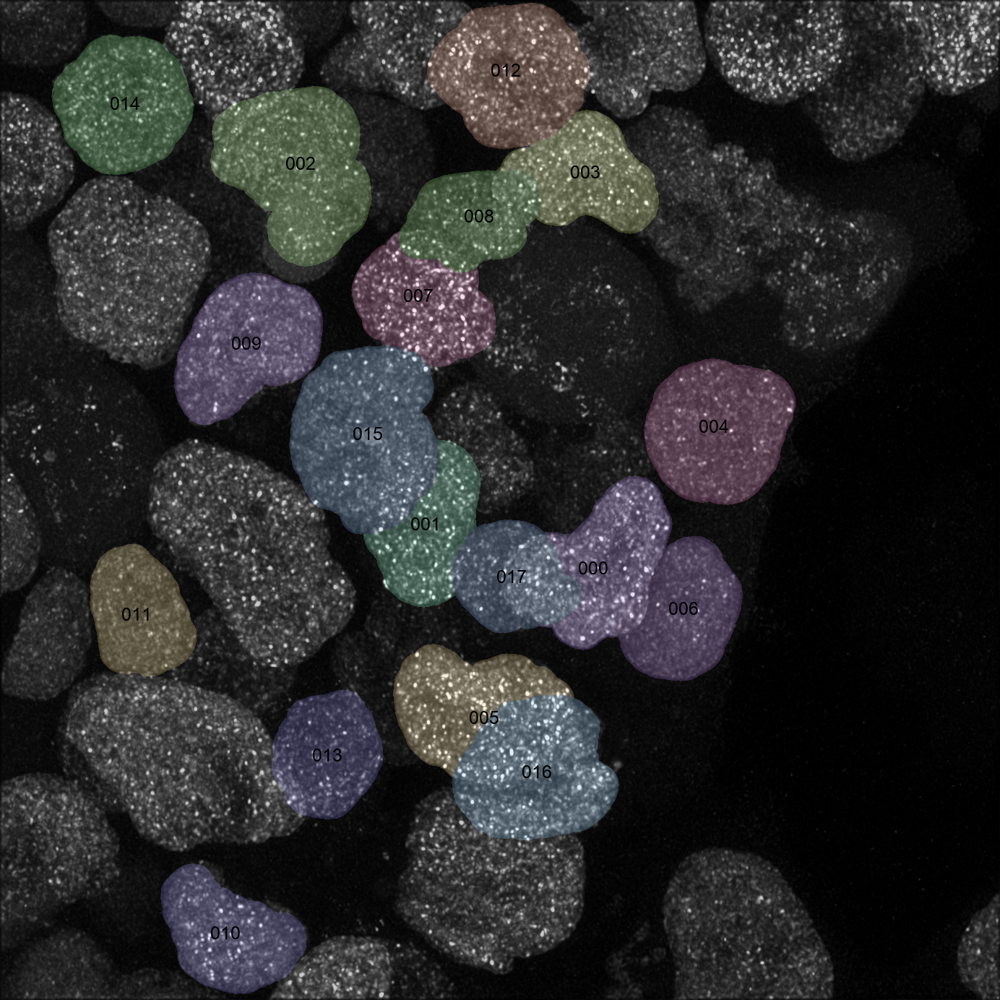

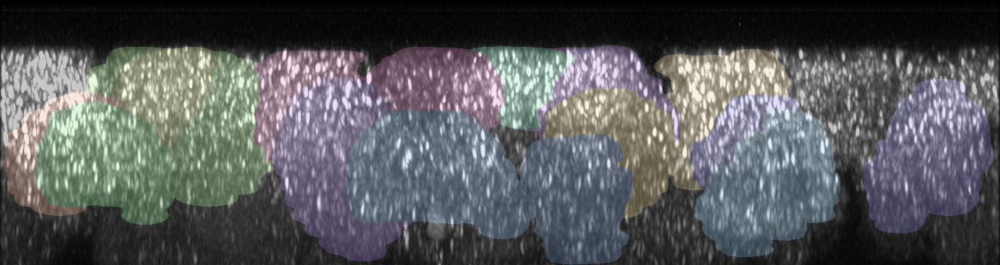

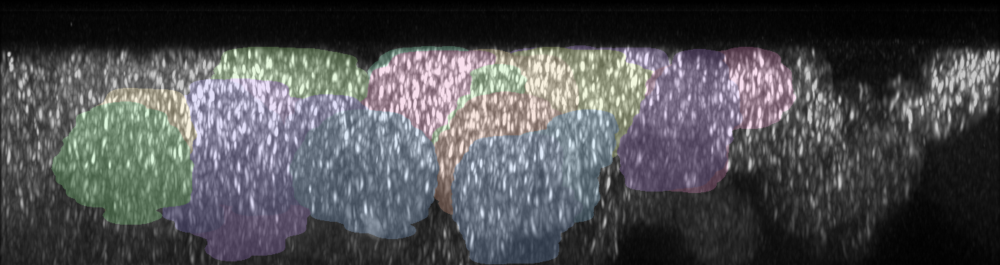

In [16]:
### Get png for figures

c = read_yaml(config)
chnl = c["segmentation"]["channel"]
kw = c["movies"]["channels"][chnl]

colors = [make_color() for _ in range(len(info))]  # fixed once
font = ImageFont.truetype(font="Arial", size=25)

# for ax in (0, 1, 2):
#     im = overlay_mip(resampled[chnl], labels, ax, colors, kw)
#     if ax == 0:
#         draw = ImageDraw.Draw(im)
#         for i in range(len(info)):
#             x, y = info[i, 2], info[i, 3]
#             draw.text(xy=(x - 20, y - 15), text=to_fmt(i), font=font, fill=(0, 0, 0))
#     display(im)

def overlay_mip(img, labels, axis, colors, chnl_kwargs, label_axis=None, transpose=False):
    """Grayscale MIP of img with labels overlaid, one fixed color per label."""
    mip = to_mip(img, **chnl_kwargs, gray=True, axis=axis)
    mip = np.clip(mip, 0, 200)
    mip_labels = np.max(labels, axis=axis if label_axis is None else label_axis)
    for i, col in enumerate(colors):
        mip[mip_labels == i] += (55 * col).astype(np.uint8)
    if transpose:
        mip = np.transpose(mip, axes=(1, 0, 2))
    return Image.fromarray(mip)

font = ImageFont.truetype(font="Arial", size=25)

for ax in (0, 1, 2):
    if ax == 0:
        # matches the working single-MIP code
        im = overlay_mip(deconvolve[chnl], labels, 0, colors, kw, label_axis=0, transpose=True)
        draw = ImageDraw.Draw(im)
        for i in range(len(info)):
            x, y = info[i, 2], info[i, 3]
            draw.text(xy=(x - 20, y - 15), text=to_fmt(i), font=font, fill=(0, 0, 0))
    else:
        im = overlay_mip(deconvolve[chnl], labels, ax, colors, kw)
    display(im)

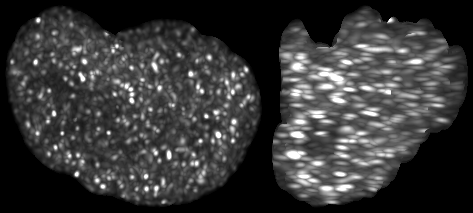

In [10]:
# Check a nucleus:
nucleus = 5

# get subset
l, u = info[nucleus,4:7].astype(int), info[nucleus,7:10].astype(int)
dcv = np.copy(deconvolve[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
rsp = np.copy(resampled[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
mask = labels[l[0]:u[0],l[1]:u[1],l[2]:u[2]] == nucleus

# make merged MIP of channels
mips = []
for chnl in range(len(rsp)):
    for axis in [0, 1]:
        mip = to_mip(dcv[chnl], mask=mask, axis=axis, gray=True, **c["movies"]["channels"][chnl])
        mips.append(np.transpose(mip, axes=(1,0,2)))  # transpose
mips = np.concatenate(mips, axis=1)
display(Image.fromarray(mips))

POLYCOMB BODY SEGMENTATION

In [11]:
print(resampled.shape, deconvolve.shape, labels.shape, info.shape)

(1, 368, 1384, 1384) (1, 368, 1384, 1384) (368, 1384, 1384) (18, 11)


In [12]:
from scipy import ndimage
# Watershed segmentation to segment particles. 
def particles_segment(dcv, rsp, mask, channel = 0, sigma=5.0, response=3.0, pct=99.0):
    """
    Defines segmentation method for particles (i.e. nuclear bodies).

    Parameters
    ----------
    dcv : numpy.ndarray
        Deconvolved signal subset around nucleus.
    rsp : numpy.ndarray
        Resampled signal subset around nucleus.
    mask : numpy.ndarray
        Mask subset for nucleus.
    channel: integer
        Channel to process bodies in.
    sigma : float,
        sigma for gaussian blurring (default: 5.0).
    response : float,
        response for standard deviation based thresholding (default: 3.0).
    pct : float, 
        percentile for thresholding (default: 99.0).

    Returns
    -------
    numpy.ndarray
        Positions of the detected pacticles.
    numpy.ndarray
        Mask for detected particles.
    """
    #print(dcv.shape, rsp.shape, mask.shape)
    
    # Background subtraction
    # Define background as gaussian blurred resampled image. Subtract this from deconvolved image.
    background = ndimage.gaussian_filter(rsp[channel].astype(np.float32), sigma=sigma, mode='nearest')
    processed_img = np.maximum(dcv[channel] - background, 0) * mask

    # Determine threshold
    mask_threshold = np.nanpercentile(dcv[channel] * mask, pct)
    mask_median = np.median(dcv[channel] * mask)
    mask_std = np.std(dcv[channel] * mask)

    final_threshold = np.mean([mask_threshold, mask_median + response * mask_std])
    #final_threshold = (mask_median + threshold_weight * mask_threshold)/(threshold_weight + 1) # Weighted average of 99th percentile and median of nuc
    particle_mask = processed_img > final_threshold

    struct = ndimage.generate_binary_structure(3, 1)  # 6-connectivity -- seems to work fine in testing a few images
    labels, n = ndimage.label(particle_mask, structure=struct)
    nuc_volume = np.sum(mask)
    nuc_mean_intensity = np.sum(rsp[channel][mask])/nuc_volume
    info = []

    info = []
    for index in range(1, n+1):
        body_mask = labels == index
        body_volume = np.sum(body_mask)
        centroid = np.mean(np.argwhere(body_mask), axis=0)
        mean_intensity = np.sum(rsp[channel][body_mask]) / body_volume

        data = [index-1, *centroid, body_volume, mean_intensity, nuc_volume, nuc_mean_intensity]
        info.append(data)

    if len(info) == 0:
        # no bodies detected — return an empty (0, 8) array so downstream
        # column_stack / savetxt still see the right number of columns
        info = np.zeros((0, 8))
    else:
        info = np.asarray(info)
    labels -= 1

    return info, labels


In [13]:
# Segment bodies in a nucleus:
nucleus = 0

# get subset
l, u = info[nucleus,4:7].astype(int), info[nucleus,7:10].astype(int)
dcv = np.copy(deconvolve[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
rsp = np.copy(resampled[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
mask = labels[l[0]:u[0],l[1]:u[1],l[2]:u[2]] == nucleus

config = "airy_config.yaml"
c = read_yaml(config)

body_info, body_labels = particles_segment(dcv, rsp, mask, **c["measuring"]["bodies"])



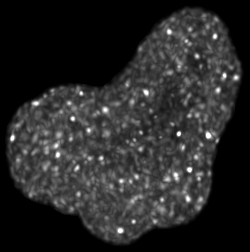

In [14]:
# Check a nucleus:
nucleus = 0

# get subset
l, u = info[nucleus,4:7].astype(int), info[nucleus,7:10].astype(int)
dcv = np.copy(deconvolve[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
rsp = np.copy(resampled[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
mask = labels[l[0]:u[0],l[1]:u[1],l[2]:u[2]] == nucleus

# make merged MIP of channels
mips = []
for chnl in range(len(dcv)):
    for axis in [0]:
        mip = to_mip(dcv[chnl], mask=mask, axis=axis, gray=True, **c["movies"]["channels"][chnl])
        mips.append(np.transpose(mip, axes=(1,0,2)))  # transpose
mips = np.concatenate(mips, axis=1)
display(Image.fromarray(mips))

In [66]:
print(deconvolve.shape, mask.shape, body_labels.shape)

(1, 368, 1384, 1384) (131, 250, 252) (131, 250, 252)


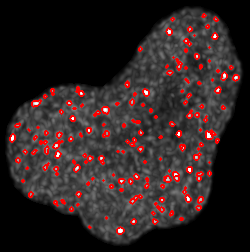

In [15]:
from skimage.segmentation import mark_boundaries
# make merged MIP of channels with body labels overlayed of a selected nucleus

nucleus = 0

# get subset
l, u = info[nucleus,4:7].astype(int), info[nucleus,7:10].astype(int)
dcv = np.copy(deconvolve[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
rsp = np.copy(resampled[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
mask = labels[l[0]:u[0],l[1]:u[1],l[2]:u[2]] == nucleus


mips = []
for chnl in range(len(dcv)):
    for axis in [0]:
        mip = to_mip(dcv[chnl], mask=mask, axis=axis, gray=True, **c["movies"]["channels"][chnl])
        labels_mip = np.max(body_labels, axis=axis)
        overlay = mark_boundaries(mip.astype(float) / 255.0, labels_mip,
                                  color=(1, 0, 0), mode='outer')
        mips.append(np.transpose(overlay, axes=(1, 0, 2)))
mips = np.concatenate(mips, axis=1)                         # was: overlay
display(Image.fromarray((mips * 255).astype(np.uint8)))     # float -> uint8

# for axis in [0, 1, 2]:
#     mip = to_mip(dcv, mask=mask, axis=axis)
#     labels_mip = np.max(body_labels, axis=axis)
#     #overlay = mark_boundaries(mip.astype(float) / 255.0, labels_mip,
#     #                                   color=(1, 0, 0), mode='outer')
# imshow(mip)


BEADS

In [ ]:
# Beads
### Read bead movie
# read bead paths and get random
paths = read_beads(beads)
path = paths[np.random.randint(0, len(paths))]

#path = "/mnt/marieshares/Miles/20260602_PcG_bodies/beads/20260602_beads_641_SR2Y-01-processed.czi"

# read frame
frame = 0
signal = read_czi(path, frame)  # reading deskew
resampled = to_isotropic(signal, **c["isotropic"])
print(path)

In [ ]:
#DETECT BEADS

# detect beads in channel
c = read_yaml(config)
device = 0
with cp.cuda.Device(device):
    positions, _ = finding(resampled, **c["beads"]["finding"])
#print(positions)


In [ ]:
chnl = 0

# make MIP
mip = to_mip(resampled[chnl], **c["movies"]["channels"][chnl], gray=True, axis=0)
mip = Image.fromarray(np.transpose(mip, axes=(1,0,2)))

# show beads
draw, radius = ImageDraw.Draw(mip), 12
for j in range(len(positions[chnl])):
    x, y = positions[chnl][j,1], positions[chnl][j,2]
    draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline="yellow", width=3)
display(mip)

In [ ]:
# make MIP and show
chnl = 0
mip = to_mip(resampled[chnl], **c["movies"]["channels"][chnl], axis=1)
mip = Image.fromarray(mip)

# show beads
draw, radius = ImageDraw.Draw(mip), 12
for j in range(len(positions[chnl])):
    z, x = positions[chnl][j,0], positions[chnl][j,2]
    draw.ellipse((x-radius, z-radius, x+radius, z+radius), outline="yellow", width=3)
display(mip)

SHOW PSF:

In [ ]:
psf_SR2Y = "AiryPSF_MKH_SR2Y.h5"
psf_before = "AiryPSFs.h5"

# get PSF parameters
lasers = c["general"]["lasers"]
kernel = read_kernel(psf_SR2Y, lasers)
shape = read_shape(psf_SR2Y, lasers)

chnl = 0

# get kernel/shape volumes
scale = 2.0
volumes = [kernel[chnl], to_ellipsoid(scale**2 * shape[chnl])]
fig, axes = plt.subplots(2, 3, figsize=(15,10))

# show all axes
k = kernel.shape[1]
for col in range(3):
    for row in range(len(volumes)):
        # make MIP
        mip = to_mip(volumes[row], axis=col,
                     color=c["movies"]["channels"][chnl]["color"])
        # show image
        h, w = mip.shape[:2]
        axes[row,col].set(xlim=(0, k), ylim=(0, k))
        axes[row,col].imshow(mip, extent=((k-w)/2, (k+w)/2, (k-h)/2, (k+h)/2))
        axes[row,col].axis("off")

        # write dimension labels
        dims = ["Z", "Y", "X"]
        dims.pop(col)
        if row == 0:
            axes[row,col].text(0.5, 1.25, dims[0], fontsize=20, color="w")
            axes[row,col].text(1.25, 0.5, dims[1], fontsize=20, color="w")
plt.tight_layout()
plt.show()